# Settings

In [44]:
#Simulation settings
using_simulation_data = False
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/npy/pig/pig_param.json"
bf_matrix_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/npy/pig/beamformed_apodized/001_pig_rectangle.npy"

#Real data settings
imported_rf_matrix_delay_unit = "um"
using_matlab_data = True
matlab_bf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/npy/pig/beamformed_apodized/bf_pig_data.mat"
interpolate_data = True

save_data = True
beamformed_filtered_matrix_name = "001_hp_svd_dataset"

# Imports

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import json
import timeit
from numba import njit
from scipy.signal import butter, lfilter
from scipy.io import loadmat

# Import parameters

In [46]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [47]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [48]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.0075120000000000004 m


# Import BF matrix

In [49]:
if using_simulation_data:
    
    bf_matrix = np.load(bf_matrix_path)
    print("Imported bf matrix with shape: ", bf_matrix.shape)

else:
    if using_matlab_data:
        bf_matrix = loadmat(matlab_bf_data_path)
        bf_matrix = list(bf_matrix.values())[-1]
        #bf_matrix = np.sum(bf_matrix, axis=2) if len(bf_matrix.shape) > 2 else bf_matrix
        print("Imported bf matrix with shape: ", bf_matrix.shape)
    else:
        bf_matrix = np.load(bf_matrix_path)
        print("Imported bf matrix with shape: ", bf_matrix.shape)


if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]


Imported bf matrix with shape:  (333, 512, 250)


/tmp/ipykernel_10757/2415395266.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(20 * np.log10(np.sum(bf_matrix, axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')
/tmp/ipykernel_10757/2415395266.py:1: RuntimeWarning: invalid value encountered in log10
  plt.imshow(20 * np.log10(np.sum(bf_matrix, axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')


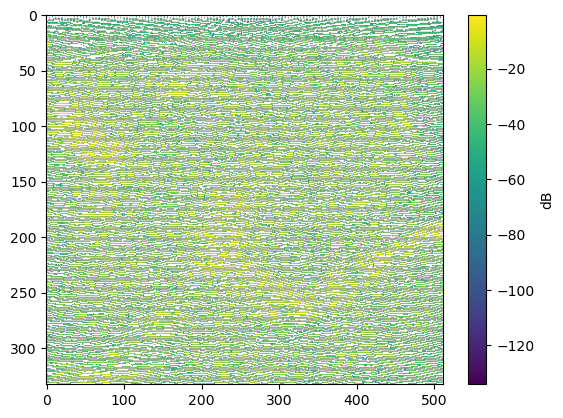

In [ ]:
plt.imshow(20 * np.log10(np.sum(np.abs(bf_matrix), axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

# Filters

## SVD

In [33]:
def filter_svd(bf, nelim):
    if nelim == 0:
        return bf, None
    #get dimensions of data
    nz, nx, nt = bf.shape
    #reshape to 2D matrix (space-time)
    m = np.reshape(bf, (nz*nx, nt))
    #remove mean from each row
    m = m - np.mean(m, axis=1, keepdims=True)
    #perform SVD decomposition
    U, S, Vt = np.linalg.svd(m, full_matrices=False)
    #create diagonal matrix from singular values
    Sf = np.diag(S)
    #set smallest singular values to zero (eliminating noise)
    Sf[:nelim, :nelim] = 0
    #reconstruct filtered matrix 
    mf = U @ Sf @ Vt
    #reshape back to 3D
    bff = np.reshape(mf, (nz, nx, nt))
    #return filtered data and singular values
    return bff, S

/tmp/ipykernel_10757/1014273449.py:2: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(20 * np.log10(np.sum(np.abs(filtered_svd),axis=2) / np.max(np.sum(np.abs(filtered_svd), axis=2))), aspect='auto', cmap='viridis')


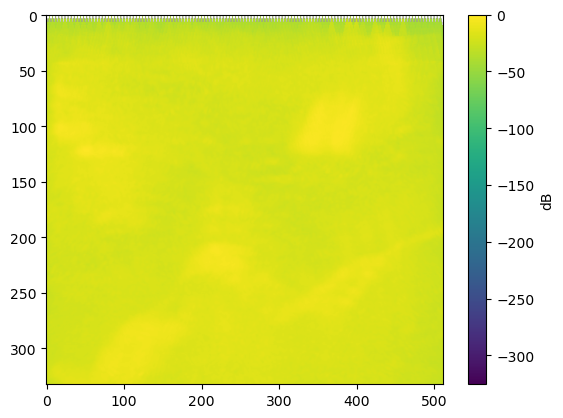

In [34]:
filtered_svd, S = filter_svd(bf_matrix, 25)
plt.imshow(20 * np.log10(np.sum(np.abs(filtered_svd),axis=2) / np.max(np.sum(np.abs(filtered_svd), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

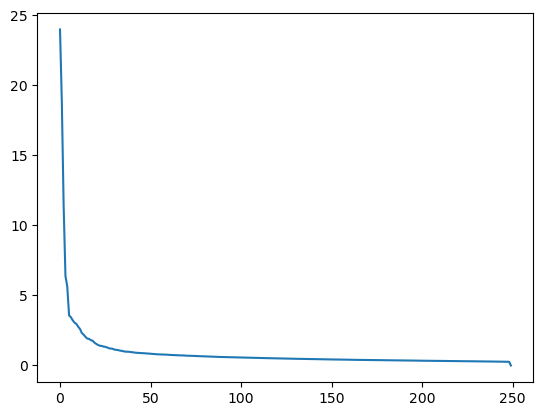

In [35]:
plt.plot(S)

## High Pass

In [36]:
def filter_hp(bf, fsam, f, nrebound):

    #subtract continuous componen
    bf  = bf -  np.mean(bf, axis=2, keepdims=True)
    #butterworth high-pass filter
    b, a = butter(3, f*0.6, 'highpass', output='ba', fs=fsam)
    #apply filter along the time dimension
    bff = lfilter(b, a, bf, axis=2)
    #the first nelim images are eliminated because the filter border effect
    if nrebound > 0:
        bff[:,:,0:nrebound] = 0
        
    return bff

/tmp/ipykernel_10757/3755893908.py:2: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp),axis=2) / np.max(np.sum(np.abs(filtered_hp),axis=2))), aspect='auto', cmap='viridis')


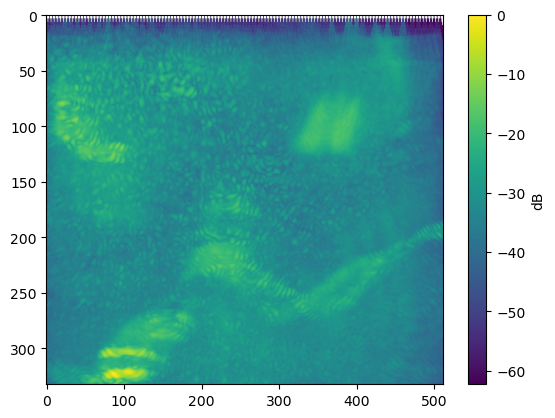

In [37]:
filtered_hp = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 15)
plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp),axis=2) / np.max(np.sum(np.abs(filtered_hp),axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

## HP + SVD

/tmp/ipykernel_10757/3614966365.py:4: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis')


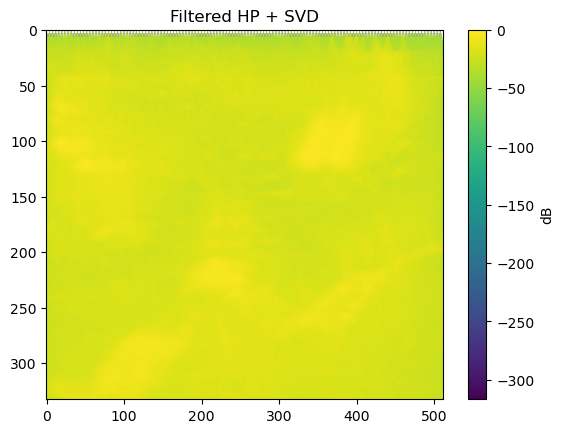

In [38]:
filtered_hp_svd = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
filtered_hp_svd, S = filter_svd(filtered_hp_svd, 25)

plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.title(f"Filtered HP + SVD")
plt.show()

# Benchmark results

In [39]:
matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))

/tmp/ipykernel_10757/4220865196.py:1: RuntimeWarning: divide by zero encountered in log10
  matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))


Signal: -21.72 dB, Noise: -inf dB, SNR: inf dB


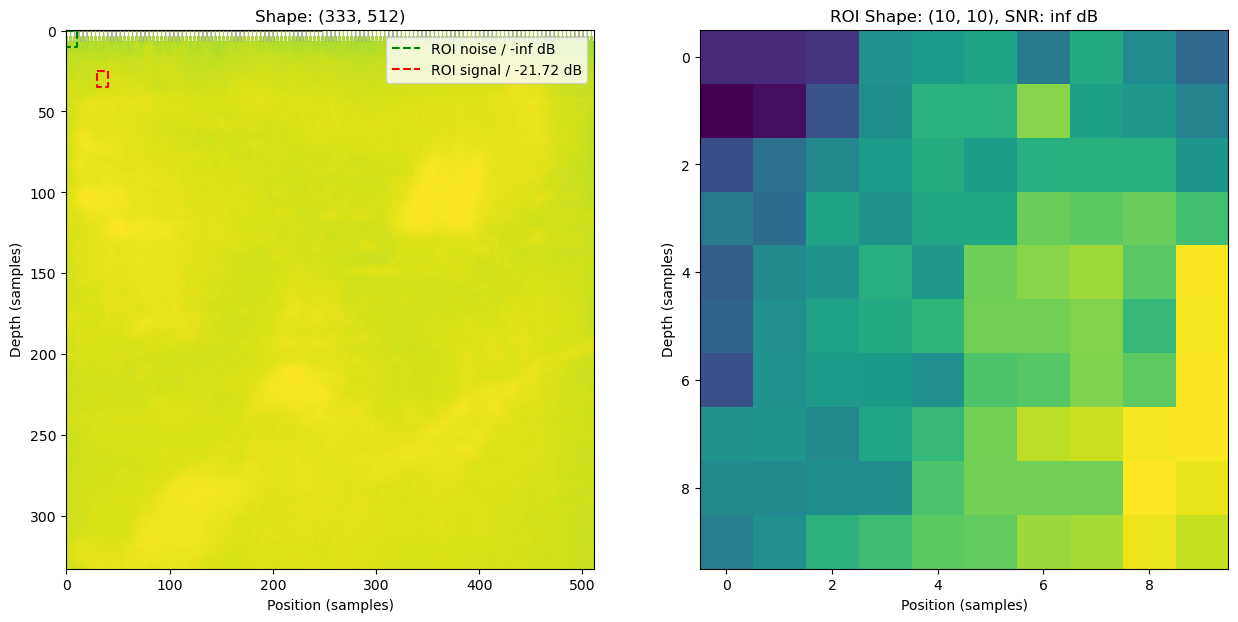

In [40]:
x0 = 30
z0 = 25
nx = 10
nz = 10

sub_plot_size = 1 if nx == None or nz == None else 2

fig, ax = plt.subplots(1, sub_plot_size, figsize=(15, 7))

if sub_plot_size == 1:
    ax = [ax]

#define noise region of interest
noise_matrix = matrix_to_analyze[0:0+nz, 0:0+nx]
Pnoise = np.mean(noise_matrix)
ax[0].plot([0, 0+nx, 0+nx, 0, 0], [0, 0, 0+nz, 0+nz, 0], 'g--', label=f'ROI noise / {Pnoise:.2f} dB')


ax[0].imshow(matrix_to_analyze, aspect='auto', cmap='viridis')
ax[0].set_xlabel("Position (samples)")
ax[0].set_ylabel("Depth (samples)")
ax[0].set_title(f"Shape: {matrix_to_analyze.shape}")

data = matrix_to_analyze[z0:z0+nz, x0:x0+nx]
Psignal= np.mean(data)

ax[0].plot([x0, x0+nx, x0+nx, x0, x0], [z0, z0, z0+nz, z0+nz, z0], 'r--', label=f'ROI signal / {Psignal:.2f} dB')
ax[0].legend()

ax[1].imshow(data, aspect='auto', cmap='viridis')
ax[1].set_xlabel("Position (samples)")
ax[1].set_ylabel("Depth (samples)")

snr_db = Psignal - Pnoise

ax[1].set_title(f"ROI Shape: {data.shape}, SNR: {snr_db:.2f} dB")

print(f"Signal: {Psignal:.2f} dB, Noise: {Pnoise:.2f} dB, SNR: {snr_db:.2f} dB")

plt.show()

# Save results

In [41]:
def save_beamformed_data(bf_matrix, filename, destination="./data_filtered/npy/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

In [42]:
save_beamformed_data(np.sum(filtered_hp_svd, axis=2), beamformed_filtered_matrix_name)

Beamformed data of shape (333, 512) saved at: ./data_filtered/npy/001_hp_svd_dataset.npy
